# Bias QC

Checks every zero of one night against a reference bias stack (made by `calib_stack.ipynb`). For every zero:
z = (zero - ref mean) / ref std, i.e. the zero minus the usual bias of every pixel, in units of the usual noise of that
pixel. For a good zero z is pure noise with sigma ~1. From z (and the zero itself):

1. **offset** [ADU]: median of (zero - ref mean), the shift of the whole frame (on wk06 frames jump by ~0.75 ADU).
2. **zsig**: sigma of z from its MAD; > 1 means the zero is noisier than usual (e.g. the interference stripes on zb08).
3. **tails**: number of pixels with z more than 5 above / below the median of z. Pure noise gives ~1 on each side.
   Only positive: cosmics or light; symmetric: interference.
4. **cosmics**: number of groups of touching pixels with z above 10 above the median of z.

T-CAM, the position in the series (LOOP), dome and mirror cover are only listed, not judged.

The reference is by default the previous block of 10 nights (night 1343 -> 1330_1340), so the checked zero is not in it.

In [1]:
import os
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from astropy.io import fits
from scipy import ndimage
from tqdm.notebook import tqdm

TEL = 'wk06'
NIGHT = 1343                        # night to check, int(JD) - 2460000
REF_START = NIGHT // 10 * 10 - 10   # reference bias stack: the previous block of 10 nights
REF_STOP = REF_START + 10

RAW_DIR = f'/data/fits/{TEL}/raw'
BIAS_DIR = os.path.expanduser(f'~/data/ocm_bias/{TEL}')

ref_mean = fits.getdata(f'{BIAS_DIR}/{TEL}_{REF_START}_{REF_STOP}_mean.fits')
ref_std = fits.getdata(f'{BIAS_DIR}/{TEL}_{REF_START}_{REF_STOP}_std.fits')
print(f'reference {TEL}_{REF_START}_{REF_STOP}: level {np.median(ref_mean):.2f}, noise {np.median(ref_std):.2f} ADU')

reference wk06_1330_1340: level 300.12, noise 7.06 ADU


## Find the zeros

In [ ]:
# old: reading every header (replaced by the frames index in the next cell)
# zero_list = []
# for f in tqdm(sorted(glob.glob(f'{RAW_DIR}/{NIGHT}/*.fits')), desc=f'night {NIGHT}'):
#     h = fits.getheader(f)
#     if h['IMAGETYP'] == 'zero':
#         zero_list.append(f)
#
# print(len(zero_list), 'zeros')

In [ ]:
# the frames of these nights from the index made by frames_index.ipynb
import pandas as pd
FRAMES_DIR = os.path.expanduser(f'~/data/ocm_frames/{TEL}')
nights = [n for n in [NIGHT] if os.path.exists(f'{FRAMES_DIR}/{n}.parquet')]
missing = [n for n in [NIGHT] if n not in nights]
if missing:
    print('nights not in the index (no frames, or run frames_index.ipynb):', missing)
frames = pd.concat([pd.read_parquet(f'{FRAMES_DIR}/{n}.parquet') for n in nights], ignore_index=True)

zero_list = list(frames.loc[frames['IMAGETYP'] == 'zero', 'file'])

print(len(zero_list), 'zeros')

## Check every zero

One row per zero. `n_pos` / `n_neg`: pixels more than 5 above / below; `cosmics`: groups of touching pixels above 10
(`ndimage.label` numbers the groups of touching True pixels, the number of groups is what we count).

In [3]:
rows = []
for f in tqdm(zero_list, desc='zeros'):
    with fits.open(f) as hdul:
        h = hdul[0].header
        data = hdul[0].data.astype(np.float32)

    diff = data - ref_mean
    z = diff / ref_std
    z = z - np.median(z)  # without the shift of the whole frame (that is the offset)

    rows.append({
        'file': os.path.basename(f),
        'time': h['DATE-OBS'][11:19],
        'loop': h.get('LOOP'),
        'tcam': h.get('T-CAM'),
        'dome': h.get('DOME-SHT'),
        'mirror': h.get('MIRR-COV'),
        'offset': np.median(diff),
        'zsig': 1.4826 * np.median(np.abs(z)),
        'n_pos': (z > 5).sum(),
        'n_neg': (z < -5).sum(),
        'cosmics': ndimage.label(z > 10)[1],
    })

qc = pd.DataFrame(rows)
pd.set_option('display.max_rows', 500)
qc.round(3)

zeros:   0%|          | 0/22 [00:00<?, ?it/s]

,file,time,loop,tcam,dome,mirror,offset,zsig,n_pos,n_neg,cosmics
0,wk06c_1343_50338.fits,00:04:51,1,-60.426,0,3,0.152,0.937,22,1,1
1,wk06c_1343_50346.fits,00:04:59,2,-60.426,0,3,-0.854,0.937,26,2,2
2,wk06c_1343_50355.fits,00:05:06,3,-60.426,0,3,-0.689,0.945,401,55,0
3,wk06c_1343_50365.fits,00:05:15,4,-60.426,0,3,0.238,0.938,12,0,1
4,wk06c_1343_50373.fits,00:05:21,5,-60.426,0,3,-0.801,0.937,11,1,0
5,wk06c_1343_50382.fits,00:05:30,6,-60.426,0,3,1.225,0.937,19,0,2
6,wk06c_1343_50390.fits,00:05:36,7,-60.426,0,3,1.166,0.938,34,1,2
7,wk06c_1343_50398.fits,00:05:43,8,-60.426,0,3,1.238,0.938,29,0,2
8,wk06c_1343_50406.fits,00:05:50,9,-60.426,0,3,0.550,0.939,10,1,0
9,wk06c_1343_50414.fits,00:05:58,10,-60.426,0,3,0.523,0.939,3,0,0


## One zero

The z map of one zero: by default the noisiest one (largest `zsig`); put a file name from the table to see another.
The histogram has the Gaussian of pure noise (sigma 1) for comparison.

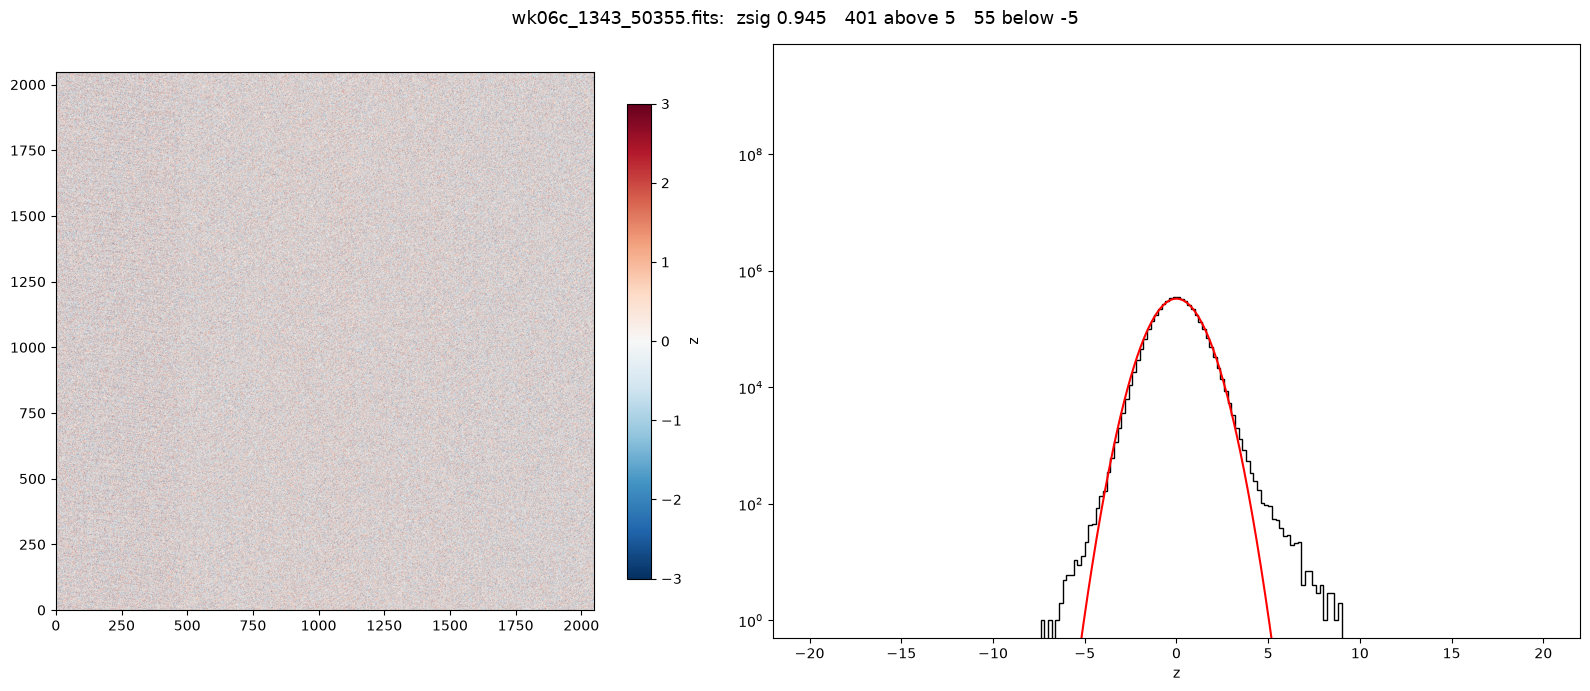

In [21]:
#f = qc.loc[qc['zsig'].idxmax(), 'file']   
#f = 'wk06c_1343_50355.fits'
f = os.path.basename(zero_list[2])

data = fits.getdata(f'{RAW_DIR}/{NIGHT}/{f}').astype(np.float32)
z = (data - ref_mean) / ref_std
z = z - np.median(z)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 7), gridspec_kw={'width_ratios': [1, 1.2]})
fig.suptitle(f'{f}:  zsig {1.4826 * np.median(np.abs(z)):.3f}   {(z > 5).sum()} above 5   {(z < -5).sum()} below -5', fontsize=13)
im = ax1.imshow(z, origin='lower', vmin=-3, vmax=3, cmap='RdBu_r')
fig.colorbar(im, ax=ax1, shrink=0.8, label='z')

v = z.ravel()
counts, edges, _ = ax2.hist(v, bins=np.arange(-20, 20.1, 0.2), histtype='step', color='k')
width = edges[1] - edges[0]
x = np.linspace(-20, 20, 2000)
ax2.plot(x, len(v) * width / np.sqrt(2 * np.pi) * np.exp(-0.5 * x ** 2), 'r')
ax2.set_yscale('log')
ax2.set_ylim(0.5, None)
ax2.set_xlabel('z')
plt.tight_layout()
plt.show()